In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
dataset = pd.read_csv("../data/clean_ressd_parcels.csv")
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 177654 entries, 0 to 177653
Data columns (total 35 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   Roll Number                         177654 non-null  int64  
 1   Full Address                        177654 non-null  str    
 2   Neighbourhood Area                  177654 non-null  str    
 3   Market Region                       177654 non-null  str    
 4   Total Living Area                   177654 non-null  float64
 5   Building Type                       177654 non-null  str    
 6   Basement                            177654 non-null  int64  
 7   Basement Finish                     177654 non-null  int64  
 8   Year Built                          177654 non-null  int64  
 9   Rooms                               177654 non-null  int64  
 10  Air Conditioning                    177654 non-null  int64  
 11  Fire Place                          1

**1- Seeing the Distribution of Total Assessed Value**

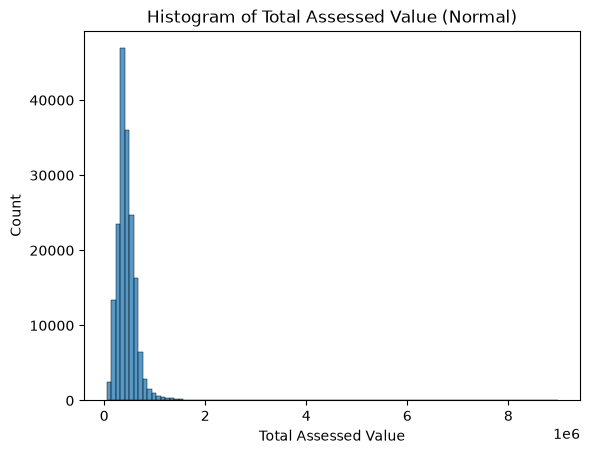

In [28]:
sns.histplot(data=dataset, x="Total Assessed Value", bins=100)
plt.title("Histogram of Total Assessed Value (Normal)")
plt.show()

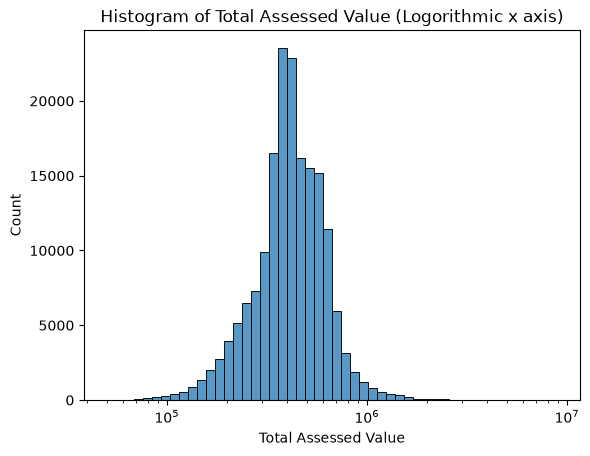

In [20]:
sns.histplot(data=dataset, x="Total Assessed Value", bins=50, log_scale=True)
plt.title("Histogram of Total Assessed Value (Logorithmic x axis)")
plt.show()

The distribution of Total Assessed Value is strongly right-skewed. Most houses are valued between about 100,000 and 1 million, while a few expensive houses extend the tail to nearly 9 million. When using a logarithmic scale, the distribution looks more balanced and closer to a bell shape, centred around 400,000. This suggests that using the log of Total Assessed Value may help the model by reducing the skewness and the influence of very expensive houses. I will compare this approach with predicting the raw assessed value during the modeling stage to see which gives better results.

**2- Seeing the Distribution of Assessed Land Area**

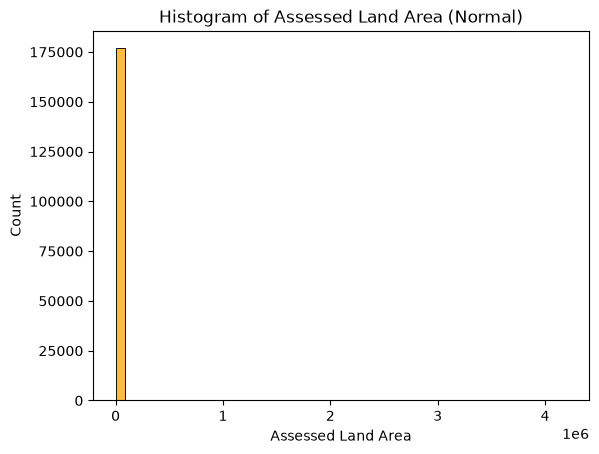

In [32]:
sns.histplot(data=dataset, x="Assessed Land Area", bins=50, color= "orange")
plt.title("Histogram of Assessed Land Area (Normal)")
plt.show()

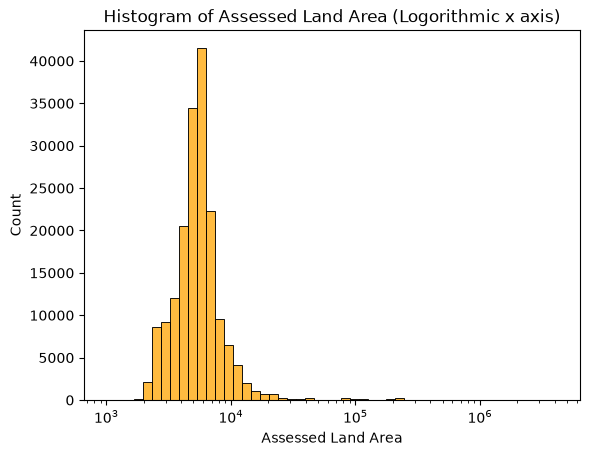

In [33]:
sns.histplot(data=dataset, x="Assessed Land Area", bins=50, log_scale=True, color= "orange" )
plt.title("Histogram of Assessed Land Area (Logorithmic x axis)")
plt.show()

Assessed Land Area is extremely right-skewed. On the raw scale, most houses fall into a single bin because a few very large lots stretch the x-axis. On a logarithmic scale, most lots are concentrated around 5,000 to 6,000 sq ft. The distribution is more compact but still right-skewed, with a small number of large lots extending beyond 100,000 sq ft. I will use the log-transformed land area for linear models and compare it with the raw values for tree-based models to see which approach gives better results.

**3- Seeing the Relationship between Total Living Area and Total Assessed Value**

we will use scatter plot to visually see the relation between them 

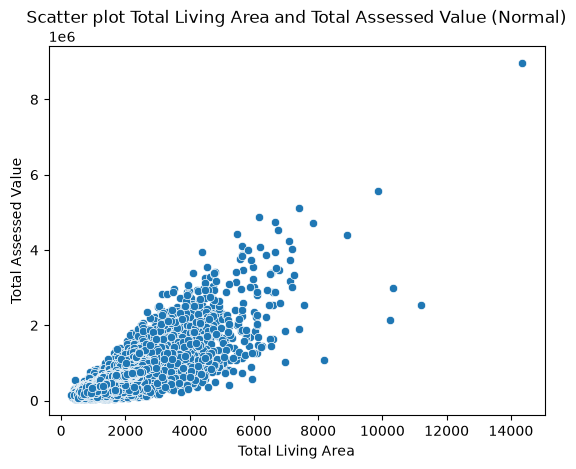

In [36]:
sns.scatterplot(data=dataset, x= "Total Living Area" , y= "Total Assessed Value")
plt.title("Scatter plot Total Living Area and Total Assessed Value (Normal)")
plt.show()

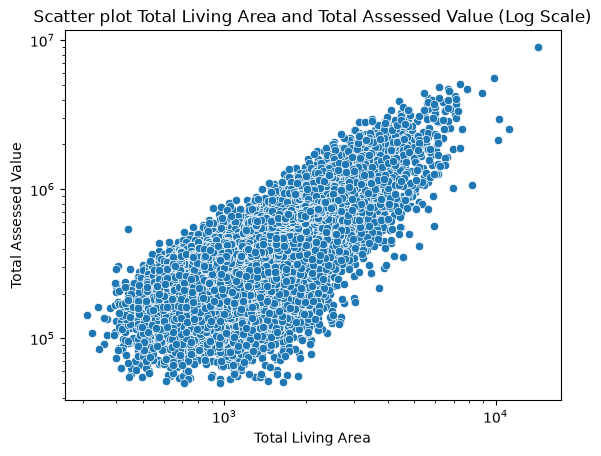

In [38]:
sns.scatterplot(data=dataset, x= "Total Living Area" , y= "Total Assessed Value")
plt.xscale("log")
plt.yscale("log")
plt.title("Scatter plot Total Living Area and Total Assessed Value (Log Scale)")
plt.show()

Assessed value generally increases as living area increases. On the raw scale, the spread of values becomes wider for larger houses. This suggests that prediction errors may be larger for bigger, more expensive houses. On a log-log scale, the points form a more even band, which supports using the log of both assessed value and living area. However, there is still a wide spread in values for houses of similar size, meaning living area alone cannot explain assessed value. Other features, such as location and age, are also needed. A few points fall far from the general trend, including some very large houses assessed at only 2 to 3 million. I will investigate these cases during error analysis.

**4- visualizing value by neighbourhood**

In [55]:
median = dataset.groupby("Neighbourhood Area")["Total Assessed Value"].median()
count= dataset.groupby("Neighbourhood Area")["Total Assessed Value"].count()
median = median[count >= 100]
count = count[count >= 100]
result = pd.DataFrame({
    "Median Assessed Value": median,
    "House Count": count
})
print(result)


                    Median Assessed Value  House Count
Neighbourhood Area                                    
AGASSIZ                          444000.0          175
AMBER TRAILS                     630000.0         1759
ARCHWOOD                         301000.0          351
ARMSTRONG POINT                  733000.0          103
ASSINIBOIA DOWNS                 944000.0          121
...                                   ...          ...
WILLIAM WHYTE                    143000.0         1314
WINDSOR PARK                     385000.0         3149
WOLSELEY                         353000.0         1947
WOODHAVEN                        451000.0          345
WORTHINGTON                      354000.0          717

[172 rows x 2 columns]


In [56]:
lowest_10 = median.sort_values().head(10)
highest_10 = median.sort_values().tail(10)

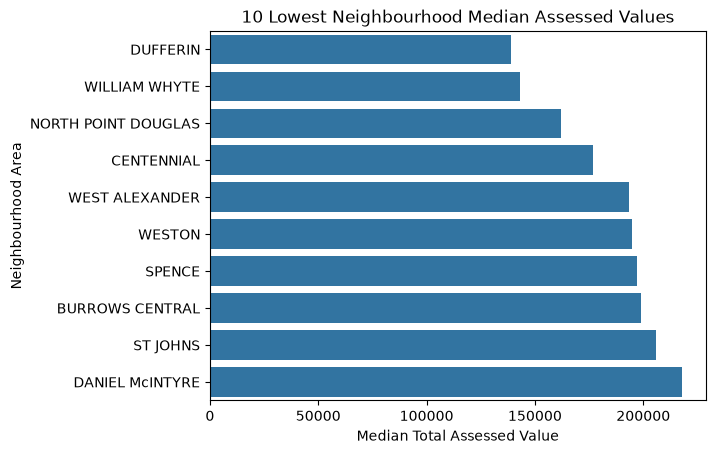

In [65]:
sns.barplot(x=lowest_10.values, y=lowest_10.index)
plt.title("10 Lowest Neighbourhood Median Assessed Values")
plt.xlabel("Median Total Assessed Value")
plt.ylabel("Neighbourhood Area")
plt.show()


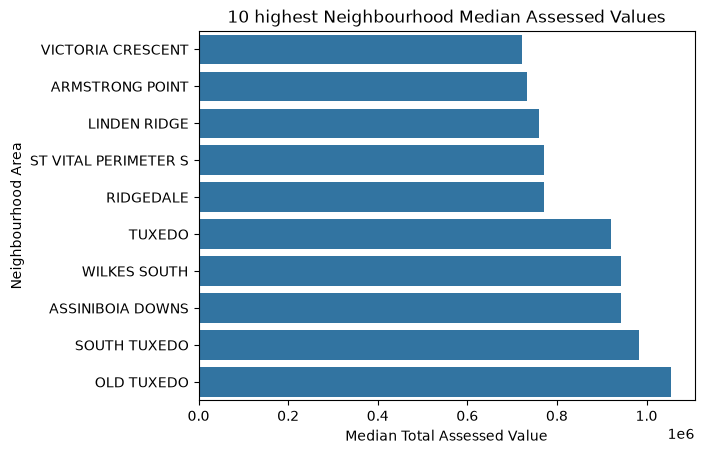

In [66]:
sns.barplot(x=highest_10 .values, y=highest_10 .index)
plt.title("10 highest Neighbourhood Median Assessed Values")
plt.xlabel("Median Total Assessed Value")
plt.ylabel("Neighbourhood Area")
plt.show()

Median assessed value varies a lot between neighbourhoods. Looking at the 172 neighbourhoods with at least 100 houses, the lowest median values are around 140,000 in Dufferin and William Whyte, while Old Tuxedo has the highest median at just over $1 million. This is a difference of roughly seven times. The lowest-value neighbourhoods are mainly inner-city areas, such as Dufferin, William Whyte, North Point Douglas, and Centennial. On the other hand, Old Tuxedo, South Tuxedo, Assiniboia Downs, and Wilkes South have some of the highest median values. This shows that location is an important factor in assessed value, so choosing how to encode neighbourhoods will be important when building the model.

**5- Correlations**

In [68]:
data_numeric = dataset.drop(columns=["Roll Number", "Centroid Lat", "Centroid Lon"]).select_dtypes(include="number")
correlation = data_numeric.corr()

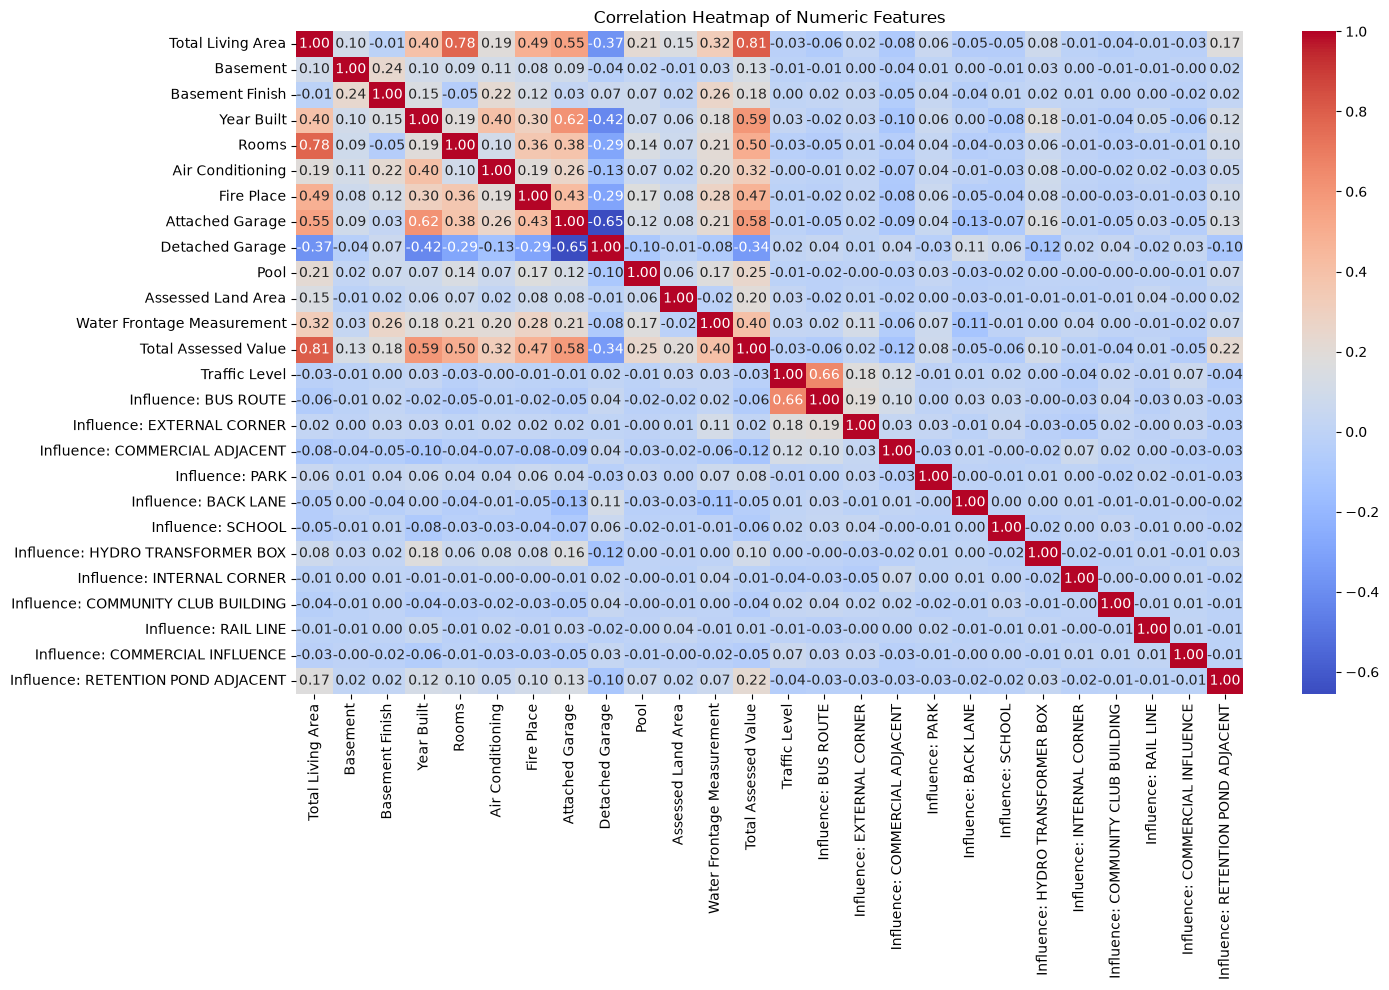

In [75]:
plt.figure(figsize=(15, 10))
sns.heatmap(correlation,annot=True,fmt=".2f",cmap="coolwarm")

plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

The strongest correlations with Total Assessed Value are Total Living Area (0.81), Year Built (0.59), and Attached Garage (0.58), followed by Rooms (0.50) and Fire Place (0.47). Total Living Area and Rooms are also highly correlated (0.78), meaning they provide some overlapping information. Detached Garage has a negative correlation with value (-0.34), which may partly reflect the age of older houses. The Property Influences flags have very weak linear correlations with assessed value. However, the heatmap only covers numeric features, so categorical features like neighbourhood are not shown, even though location appears to be an important factor.

**6- a map of houses coloured by value**

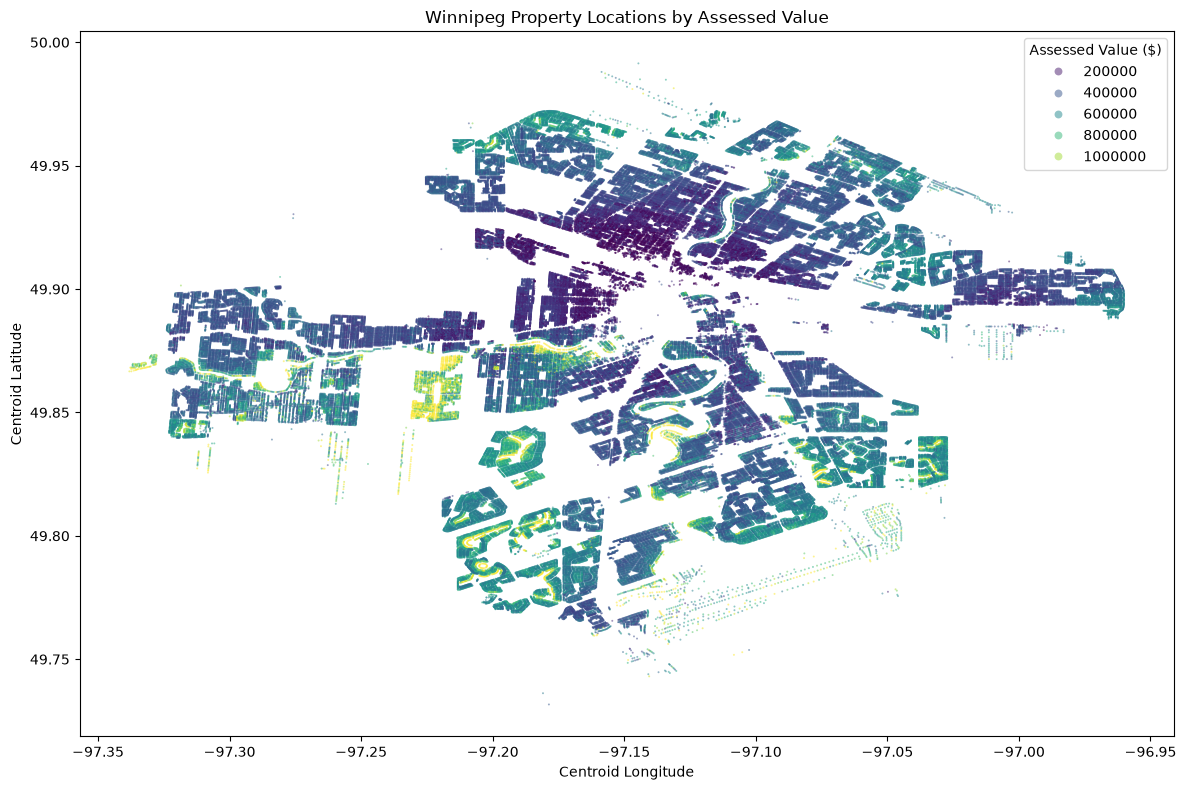

In [82]:

lower = dataset["Total Assessed Value"].quantile(0.01)
upper = dataset["Total Assessed Value"].quantile(0.99)

# Clip values for colouring so expensive outliers don't wash out the plot
# Value Clipped is a copy of Total Assessed Value used only for colouring this map. It is not saved to the cleaned file and is not used in modeling.
dataset["Value Clipped"] = dataset["Total Assessed Value"].clip(lower=lower, upper=upper)

plt.figure(figsize=(12, 8))
sns.scatterplot(data=dataset,x="Centroid Lon",y="Centroid Lat",hue="Value Clipped",palette="viridis",hue_norm=(lower, upper),s=2,alpha=0.5,linewidth=0)

plt.title("Winnipeg Property Locations by Assessed Value")
plt.xlabel("Centroid Longitude")
plt.ylabel("Centroid Latitude")
plt.legend(title="Assessed Value ($)", markerscale=4)
plt.tight_layout()
plt.show()


Each house was plotted using its coordinates and coloured by assessed value. Values were clipped to the 1st and 99th percentiles (129,000 to 1.14 million) to prevent expensive houses from washing out the colours. The points form the outline of Winnipeg, with gaps around parks, industrial areas, and rivers. No points fall far outside the city, so the coordinates appear reasonable. Values are generally lower in central and northern areas and higher along the river corridors and in the south-west. This matches the neighbourhood chart and confirms that location is an important feature to consider when building the model.

**7- features and value**

In [90]:
features = ["Air Conditioning","Pool","Fire Place","Attached Garage","Detached Garage","Basement Finish"]

results = []

for feature in features:
    median = dataset.groupby(feature)["Total Assessed Value"].median()

    for value, assessed_value in median.items():
        results.append({
            "Feature": feature,
            "Status": "With" if value == 1 else "Without",
            "Median Assessed Value": assessed_value
        })

comparison = pd.DataFrame(results)

comparison

,Feature,Status,Median Assessed Value
0,Air Conditioning,Without,314000.0
1,Air Conditioning,With,440000.0
2,Pool,Without,407000.0
3,Pool,With,603000.0
4,Fire Place,Without,371000.0
5,Fire Place,With,543000.0
6,Attached Garage,Without,361000.0
7,Attached Garage,With,568000.0
8,Detached Garage,Without,500000.0
9,Detached Garage,With,370000.0


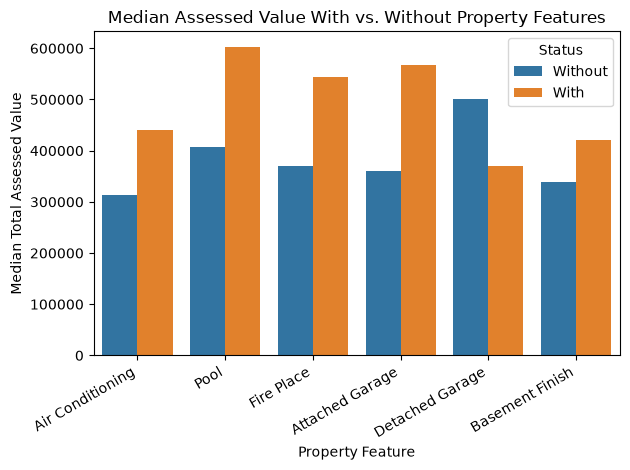

In [92]:
sns.barplot(data=comparison,x="Feature",y="Median Assessed Value",hue="Status")

plt.title("Median Assessed Value With vs. Without Property Features")
plt.xlabel("Property Feature")
plt.ylabel("Median Total Assessed Value")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Houses with an attached garage, pool, or fire place have higher median assessed values, with gaps of about 207,000, 196,000, and 172,000, respectively. Air conditioning and a finished basement also show gaps of 126,000 and 83,000. Detached garages show the opposite pattern, with lower median values (370,000 vs. 500,000), possibly because they are more common in older houses or cheaper neighbourhoods. These differences are not necessarily caused by the features themselves, since house size and location also affect value. The model will need to account for these factors.

## Summary

- **Target distribution:** Total Assessed Value is strongly right-skewed and looks closer to a bell shape on a log scale. Assessed Land Area shows a similar pattern.
- **Main predictor:** Total Living Area has the strongest correlation with assessed value (0.81), followed by Year Built and Attached Garage.
- **Neighbourhood:** Median assessed values vary by roughly seven times between the cheapest and most expensive neighbourhoods, showing that location matters.
- **Geographic patterns:** The map shows clear differences in property values across Winnipeg.
- **Property features:** Houses with a pool, attached garage, or fire place tend to have higher assessed values, although these differences may also reflect house size and location.
- **Modeling plan:** Predict the log of assessed value, use log-transformed land area for linear models, and carefully encode neighbourhood.